# **Notebook 2: Model Quality and Prediction Latency**

**Overall Notebook Description:** Compare eight CPU models on one frozen seven-feature SQL population. Report false alerts, caught positives, ranking quality, training cost, warm single-window latency, batch throughput and serialized size. The companion data audit selects a future data source separately; these experiments keep the current source fixed.

---

# **Part 1: Configure the Model Comparison**

**Part 1 Description:** Recent research, including [TabArena (2025)](https://arxiv.org/abs/2506.16791), identifies boosted trees as strong options for tabular machine learning. Other research also supports evaluating XGBoost, LightGBM, and CatBoost. To make a fair comparison, this study also includes linear models and Extra Trees to evaluate differences in prediction performance and computational cost. Newer approaches, such as [TabPFN-3.5 (2026)](https://arxiv.org/abs/2609.17895) and [TabDPT-Turbo (2026)](https://arxiv.org/abs/2608.01400), are also worth considering. However, they are outside the scope of this CPU-based study and would require separate testing.

A more detailed research comparison is available in `docs/model_research_2026-10-24.md`. Published results are used to guide model selection, not to predict how models will perform on this dataset.

### **Imports, Configuration, and Frozen Inputs**

In [1]:
%matplotlib inline
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from cybershield.db import ROOT, file_hash
from cybershield.research import RESEARCH, load_snapshot, split_masks
from cybershield.evaluate import FEATURES
data, protocol, manifest = load_snapshot()
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
FIGURES = RESEARCH / 'figures'; FIGURES.mkdir(exist_ok=True)
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
display(pd.Series(manifest, name='Frozen experiment').drop('files').to_frame())

,Frozen experiment
experiment_id,45b7feae-ffe5-4c71-998c-b87afe724bd6
feature_run_id,464b8de2-25da-4368-9333-eeade277dc70
schema,cs_tuesday
snapshot_created_utc,2026-10-25T03:12:01.622526+00:00
source_run_directory,reports\runs\real_20261025T022514Z_660a4c30
read_only_research,True


---

# **Part 2: Define the Population, Models, and Threshold Protocol**

**Part 2 Description:** Preprocessing used training data only, including median imputation, scaling, and log1p transformations for linear models. Class weights were also calculated from training data, while calibration and development sets retained their natural class distributions. Models used fixed configurations without hyperparameter searches or development-based tuning.

Cutoffs were calibrated on benign calibration windows, targeting a 1% empirical false-alert rate. This does not guarantee future performance. Each model was fitted three times using one CPU thread and a seeded random order. SVM margins were treated as scores, not probabilities. Data masks were validated against chronological intervals, although campaign overlap remains a limitation.

### **Verify the Chronological Roles and Input Features**

In [2]:
masks = split_masks(data, protocol['config'])
support = pd.DataFrame([{ 'role':name,'windows':int(mask.sum()),
    'positive_windows':int(data.loc[mask,'attack_flows'].gt(0).sum()),
    'sources':int(data.loc[mask,'src_ip'].nunique())} for name,mask in masks.items()])
display(support)
display(pd.Series(protocol['config']['splits']).to_frame('Recorded-clock interval'))
print('Inputs:', FEATURES)
print('Raw identity/time/history/labels/predictions are excluded from model inputs.')

,role,windows,positive_windows,sources
0,train,3493,6,2020
1,calibration,1245,3,948
2,development,3413,6,1895
3,benign_calibration,1242,0,947


,Recorded-clock interval
train,"[2017-07-04 08:55:00, 2017-07-04 09:45:00]"
calibration,"[2017-07-04 09:45:00, 2017-07-04 10:00:00]"
development,"[2017-07-04 10:00:00, 2017-07-04 11:00:00]"


Inputs: ['flow_count', 'unique_ports', 'unique_destinations', 'service_flows', 'packets', 'bytes', 'mean_duration_us']
Raw identity/time/history/labels/predictions are excluded from model inputs.


### **Population Interpretation**

The role table separates training, calibration, development, and the benign-only calibration subset. Different rows do not imply independent campaigns. Six correlated development positives constrain any interpretation of model ranking.

### **Freeze Preprocessing, Class Weights, and Model Configurations**

In [3]:
from cybershield.research import candidates
train_y = data.loc[masks['train'],'attack_flows'].gt(0)
candidate_models = candidates(protocol['config']['seed'],(~train_y).sum()/train_y.sum())
for name, model in candidate_models.items():
    print(name, '\n ',model,'\n')

Logistic regression 
  Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('functiontransformer',
                 FunctionTransformer(func=<ufunc 'log1p'>)),
                ('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=1, class_weight='balanced', max_iter=2000,
                                    random_state=1729))]) 

Linear SVM 
  Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('functiontransformer',
                 FunctionTransformer(func=<ufunc 'log1p'>)),
                ('standardscaler', StandardScaler()),
                ('linearsvc',
                 LinearSVC(C=1, class_weight='balanced', max_iter=10000,
                           random_state=1729))]) 

Random forest 
  Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('randomforestclassifier',
                 RandomForestClassifier(class_weight

### **Configuration Interpretation**

Each model receives the same seven inputs and role membership. Transformations and class weights are fitted from training data; thresholds use benign calibration scores. Candidate families require different preprocessing, which is included in their pipeline timing.

---

# **Part 3: Execute the Quality and Timing Experiment**

**Part 3 Description:** Each run recalculates results and saves raw measurements. Methods are warmed up five times before testing. Measurements include 60 single-row calls and 25 calls for each larger batch size (32, 256, and the full development set). Model order is randomized, and all models receive the same sampled inputs.

Pipeline timing includes preprocessing and model scoring, while model-only timing excludes preprocessing. Both include Python scoring and result extraction. SQL, HTTP, model loading, feature creation, and waiting between windows are excluded. As explained in the [detection latency research](https://link.springer.com/article/10.1007/s10664-025-10766-3), live attack-to-alert delay is a separate measurement that this offline study cannot evaluate.

P95 represents observed local latency, not a production guarantee. Three training runs are sufficient for median and maximum comparisons but not reliable estimates of training-time extremes.

### **Apply Timing Controls and Run Fixed Comparisons**


In [4]:
import warnings
from cybershield.research import benchmark
# LightGBM assigns generated feature names even when its input is a NumPy array.
# All pipeline stages here use the same explicitly ordered FEATURES; suppress only this known warning.
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='X does not have valid feature names, but LGBMClassifier was fitted with feature names')
    comparison, latency, baselines, scores, environment = benchmark(data, protocol)
display(pd.Series(environment).drop('versions').to_frame('Environment / protocol'))
display(pd.Series(environment['versions']).to_frame('Installed version'))

,Environment / protocol
status,development_only
seed,1729
threads,1
feature_columns,"[flow_count, unique_ports, unique_destinations..."
created_utc,2026-10-25T03:16:15.082156+00:00
cpu,"Intel64 Family 6 Model 183 Stepping 1, Genuine..."
logical_cpus,32
physical_cpus,24
ram_bytes,34053414912
os,Windows-11-10.0.26200-SP0


,Installed version
numpy,2.5.4
pandas,2.3.3
scikit-learn,1.9.1
lightgbm,4.7.0
xgboost,3.4.1
catboost,1.2.10
psutil,7.2.2
threadpoolctl,3.7.0
nbclient,0.11.0


### **Runtime Record Interpretation**

The saved environment, versions, thread controls, and raw repetitions describe the measured execution. These outputs are retained from that experiment. Single-window calls, batch amortization, and training fits represent different compute costs; none measures live attack-onset-to-alert delay.

---

# **Part 4: Compare Detection Quality and False Alerts**

**Part 4 Description:** Use caught/total positives and false/total benign alerts alongside average precision. Accuracy is dominated by benign windows. Ranking metrics do not establish event-level early detection. Precision-recall curves here contain only six positive observations and describe this development slice.

### **Review Confusion Counts and Precision–Recall Curves**

,method,tp,fn,fp,tn,precision,recall,f1,average_precision,false_positives_per_1000,calibration_false_alerts,cutoff
0,Random forest,6,0,61,3346,0.089552,1.000000,0.164384,0.869048,17.904315,12,0.009991
1,Extra trees,6,0,78,3329,0.071429,1.000000,0.133333,0.860360,22.894042,12,0.214365
2,LightGBM,5,1,31,3376,0.138889,0.833333,0.238095,0.834096,9.098914,12,0.000022
3,Histogram boosting,5,1,39,3368,0.113636,0.833333,0.200000,0.771144,11.447021,12,0.000100
4,CatBoost,5,1,57,3350,0.080645,0.833333,0.147059,0.834399,16.730261,12,0.016493
5,Logistic regression,5,1,64,3343,0.072464,0.833333,0.133333,0.842857,18.784855,12,0.001193
6,Linear SVM,5,1,118,3289,0.040650,0.833333,0.077519,0.833687,34.634576,12,-0.998202
7,XGBoost,4,2,0,3407,1.000000,0.666667,0.800000,0.667253,0.000000,1242,0.001414


,method,tp,fn,fp,tn,precision,recall,average_precision
0,sql_combined,5,1,21,3386,0.192308,0.833333,0.833626
1,flow_count_baseline,4,2,34,3373,0.105263,0.666667,0.086734
2,always_benign,0,6,0,3407,NaN,0.000000,0.001758
3,random_baseline,0,6,28,3379,0.000000,0.000000,0.001957


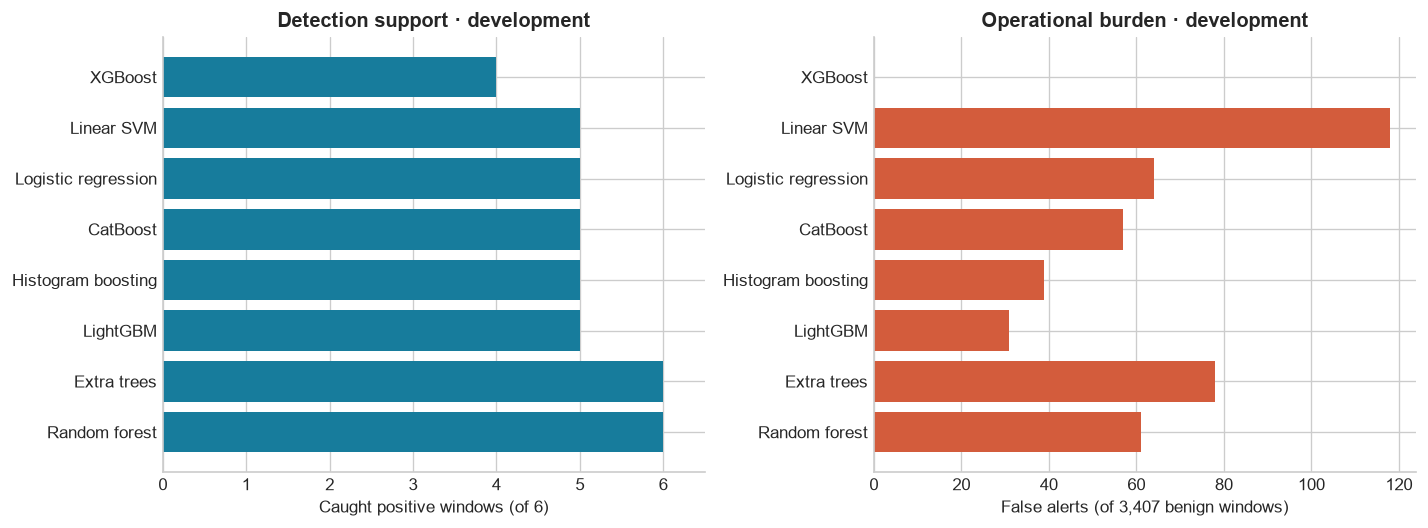

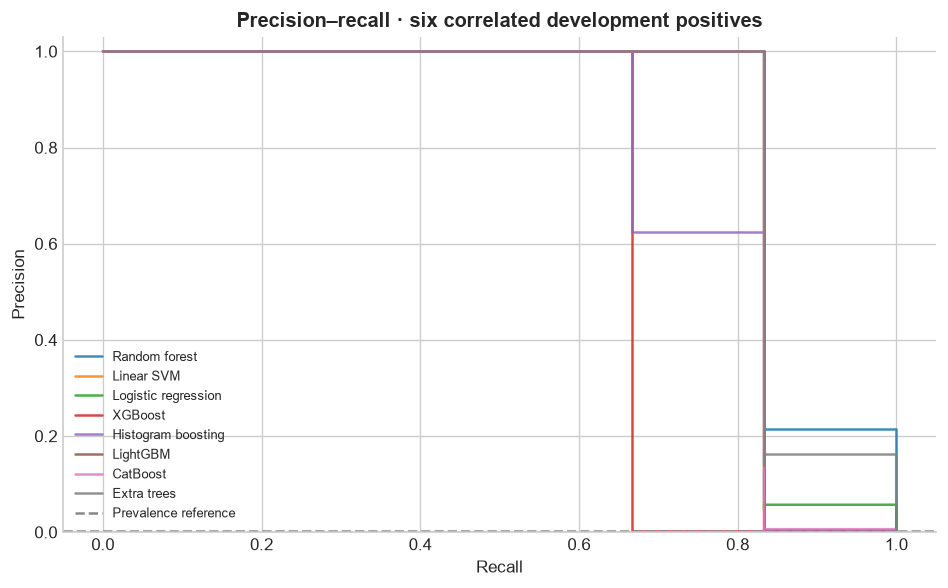

In [5]:
columns = ['method','tp','fn','fp','tn','precision','recall','f1','average_precision',
           'false_positives_per_1000','calibration_false_alerts','cutoff']
display(comparison[columns].sort_values(['fn','fp','method']).reset_index(drop=True))
display(baselines[['method','tp','fn','fp','tn','precision','recall','average_precision']])
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
ordered = comparison.sort_values(['fn','fp','method'])
axes[0].barh(ordered.method,ordered.tp,color='#177c9c')
axes[0].set(xlabel='Caught positive windows (of 6)',xlim=(0,6.5),title='Detection support · development')
axes[1].barh(ordered.method,ordered.fp,color='#d35c3c')
axes[1].set(xlabel='False alerts (of 3,407 benign windows)',title='Operational burden · development')
finish(fig,'models_01_quality')
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(figsize=(8,5))
for name in comparison.method:
    precision, recall, _ = precision_recall_curve(scores.is_attack,scores[name])
    ax.step(recall,precision,where='post',label=name,alpha=.85)
ax.axhline(scores.is_attack.mean(),color='#888888',ls='--',label='Prevalence reference')
ax.set(xlabel='Recall',ylabel='Precision',title='Precision–recall · six correlated development positives',ylim=(0,1.03))
ax.legend(fontsize=8)
finish(fig,'models_02_precision_recall')

### **Detection Quality Interpretation**

Compare caught positives with false alerts on the identical development population. A method catching all six windows has covered this slice, rather than six independent attacks. The SQL baselines remain meaningful quality references. These counts and curves do not establish a generalizable accuracy winner.

---

# **Part 5: Examine Latency, Throughput, and Training Cost**

**Part 5 Description:** Do not confuse an amortized microsecond cost per row in a large batch with the millisecond cost of one query. Model-size values are uncompressed serialized joblib bytes, not live memory. Pipeline and model-only calls use their appropriate fitted transformations. The SQL references above have no Python timing bars because their actual execution path differs.

### **Compare Warm Single-Window and Batched Prediction Costs**

,method,single_pipeline_median_ms,single_pipeline_p95_ms,fit_median_ms,fit_max_ms,serialized_bytes,pareto_observed
1,Linear SVM,1.10070,1.669285,27.7337,29.1131,1997,True
2,Logistic regression,1.10975,1.762860,19.7976,23.0347,2129,True
5,LightGBM,1.57775,1.958850,82.9240,85.5533,121152,True
3,XGBoost,1.45425,2.103200,115.4039,147.8161,157046,True
6,CatBoost,1.80800,2.408955,1186.4974,1347.5988,228262,False
4,Histogram boosting,4.50720,5.571580,561.5005,569.5085,200569,False
7,Extra trees,24.43670,28.835990,450.1151,455.6464,262578,True
0,Random forest,23.53635,29.768015,686.5031,699.5157,185458,True


,method,scope,batch_size,median_ms,p95_ms,calls,amortized_us_per_row,rows_per_second
0,Linear SVM,model_only,1,0.25420,0.487485,60,254.200000,3933.910307
1,Logistic regression,model_only,1,0.32295,0.438615,60,322.950000,3096.454560
2,XGBoost,model_only,1,0.81640,1.216655,60,816.400000,1224.889760
3,LightGBM,model_only,1,0.95430,1.378650,60,954.300000,1047.888505
4,CatBoost,model_only,1,1.24655,1.653915,60,1246.550000,802.214111
...,...,...,...,...,...,...,...,...
59,XGBoost,pipeline,3413,7.20460,10.077660,25,2.110929,473725.120062
60,LightGBM,pipeline,3413,28.39910,33.557860,25,8.320861,120179.864855
61,Histogram boosting,pipeline,3413,31.94780,36.931060,25,9.360621,106830.517281
62,Random forest,pipeline,3413,33.90750,40.014680,25,9.934808,100656.197007


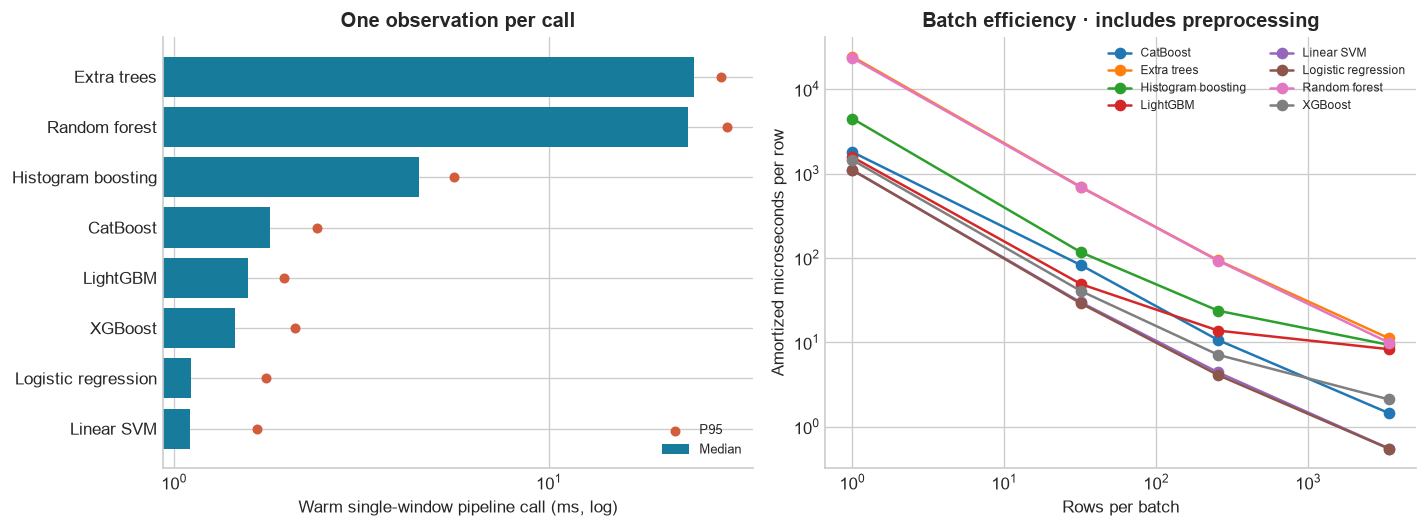

In [6]:
display(comparison[['method','single_pipeline_median_ms','single_pipeline_p95_ms',
    'fit_median_ms','fit_max_ms','serialized_bytes','pareto_observed']].sort_values('single_pipeline_p95_ms'))
display(latency.sort_values(['scope','batch_size','median_ms']).reset_index(drop=True))
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
ordered = comparison.sort_values('single_pipeline_median_ms')
axes[0].barh(ordered.method,ordered.single_pipeline_median_ms,color='#177c9c',label='Median')
axes[0].scatter(ordered.single_pipeline_p95_ms,ordered.method,color='#d35c3c',s=25,label='P95',zorder=3)
axes[0].set(xscale='log',xlabel='Warm single-window pipeline call (ms, log)',title='One observation per call')
axes[0].legend(fontsize=8)
for name,group in latency.query("scope == 'pipeline'").groupby('method'):
    axes[1].plot(group.batch_size,group.amortized_us_per_row,marker='o',label=name)
axes[1].set(xscale='log',yscale='log',xlabel='Rows per batch',ylabel='Amortized microseconds per row',title='Batch efficiency · includes preprocessing')
axes[1].legend(fontsize=7,ncol=2)
finish(fig,'models_03_latency')

### **Prediction Latency Interpretation**

Use median and empirical P95 for a single-window query; use throughput and amortized per-row cost for batches. Preprocessing is included in pipeline costs and excluded from estimator-only costs. Faster batch processing does not establish lower single-query latency, and local percentiles are not service-level guarantees.

### **Review SQL Feature Retrieval as a Separate Measurement**

In [7]:
sql_times = pd.read_csv(RESEARCH / 'sql_audit/feature_fetch_latency.csv')
display(sql_times)
display(pd.Series({'rows_per_fetch':int(sql_times.rows.iloc[0]),
    'warm_fetch_dataframe_median_ms':sql_times.sql_fetch_dataframe_ms.median(),
    'warm_fetch_dataframe_empirical_p95_ms':sql_times.sql_fetch_dataframe_ms.quantile(.95)}).to_frame('Separate SQL measurement'))
print('Retrieves existing feature rows; excludes feature-table construction and window/flow availability wait.')

,repeat,rows,sql_fetch_dataframe_ms
0,0,11398,41.2977
1,1,11398,47.5606
2,2,11398,50.1100
3,3,11398,61.9621
4,4,11398,45.4930
5,5,11398,43.1350
6,6,11398,41.2294
7,7,11398,52.8443
8,8,11398,38.9542
9,9,11398,40.6933


,Separate SQL measurement
rows_per_fetch,11398.00000
warm_fetch_dataframe_median_ms,44.31400
warm_fetch_dataframe_empirical_p95_ms,57.85909


Retrieves existing feature rows; excludes feature-table construction and window/flow availability wait.


### **SQL Measurement Interpretation**

This measurement retrieves the already-materialized feature population and constructs a DataFrame. It does not rebuild features or measure the serving path. Its batch size and scope differ from a single model call, so the numbers should not be added as though they formed an end-to-end request benchmark.

---

# **Part 6: Assess the Observed Quality and Latency Tradeoff**

**Part 6 Description:** Mark a method non-dominated only if no other tested method has no more missed positives, no more false alerts and no greater warm single-window P95, with a strict improvement in at least one. Average precision, training cost and size remain visible tradeoffs outside that particular frontier definition. This does not establish statistical superiority; latency variation alone can move frontier membership.

### **Identify Non-Dominated Candidate Configurations**

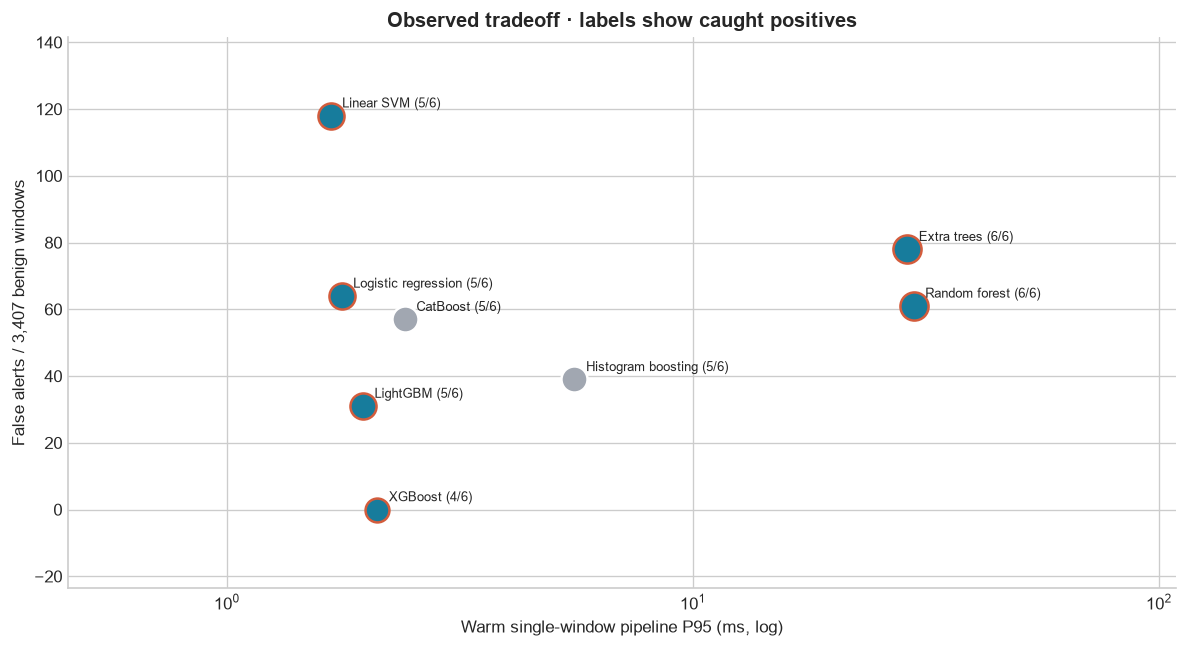

,method,tp,fp,average_precision,single_pipeline_p95_ms,fit_median_ms,serialized_bytes
0,Random forest,6,61,0.869048,29.768015,686.5031,185458
1,Linear SVM,5,118,0.833687,1.669285,27.7337,1997
2,Logistic regression,5,64,0.842857,1.762860,19.7976,2129
3,XGBoost,4,0,0.667253,2.103200,115.4039,157046
5,LightGBM,5,31,0.834096,1.958850,82.9240,121152
7,Extra trees,6,78,0.860360,28.835990,450.1151,262578


In [8]:
fig, ax = plt.subplots(figsize=(10,5.5))
for row in comparison.itertuples():
    ax.scatter(row.single_pipeline_p95_ms,row.fp,s=45+40*row.tp,
        color='#177c9c' if row.pareto_observed else '#a1a7b1',
        edgecolor='#d35c3c' if row.pareto_observed else 'white',linewidth=1.5)
    ax.annotate(f'{row.method} ({row.tp}/6)',(row.single_pipeline_p95_ms,row.fp),
        xytext=(7,5),textcoords='offset points',fontsize=8)
ax.set(xscale='log',xlabel='Warm single-window pipeline P95 (ms, log)',
       ylabel='False alerts / 3,407 benign windows',title='Observed tradeoff · labels show caught positives')
ax.margins(x=.45,y=.2)
finish(fig,'models_04_frontier')
display(comparison.loc[comparison.pareto_observed,['method','tp','fp','average_precision',
    'single_pipeline_p95_ms','fit_median_ms','serialized_bytes']])

### **Frontier Interpretation**

A highlighted configuration is non-dominated only among these candidates for missed positives, false alerts, and warm single-window P95. It is not necessarily best in average precision, fitting cost, or size. Sparse positives and timing variability can change frontier membership; the plot supports a shortlist for a better-supported study.

---

# **Part 7: Conclusion**

Read the measured tables as a shortlist for a better-supported study, not a model selection certificate. A small false-alert count can coexist with poor recall; very fast predictions cannot compensate for missed attacks. The SQL combined rule remains a meaningful quality reference. No model is promoted into the application by this notebook.

The data audit recommends a corrected-release adapter before widening the ML study. Resolve attempted labels and UTC/duration mappings, then predefine episode-separated development/validation populations and an independent final holdout with sufficient attack support. Preserve all rows' natural prevalence and report attack-family results and group-level uncertainty. Rebenchmark latency on the intended deployment hardware, including cold starts, feature construction and the serving path if an online system is built.

Full outputs: `reports/research/models/`; figures: `reports/research/figures/`. Fixed parameters, environment versions, raw fit/call timings, per-window scores, cutoffs and the frozen input hashes make these results inspectable. Latencies will vary on rerun.

---